In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
from config.paths import EXTRACTED_ROOT

DATA_ROOT = EXTRACTED_ROOT
CONF_THRESH = 0.6  # min RHE confidence to trust a mu/nu label
LOW_THRESH = 0.6  # mu/nu below this counts as low traversability

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 220)


def mission_stats(d: Path) -> dict | None:
    """Per-mission summary row, or None if core labels are missing."""
    try:
        trav = np.load(d / "trav_labels.npy")
        ts = np.load(d / "timestamp.npy").astype(float)
    except FileNotFoundError:
        return None
    mu, nu = trav[:, 0], trav[:, 1]

    try:
        mu_c = np.load(d / "mu_confidences.npy")
        nu_c = np.load(d / "nu_confidences.npy")
    except FileNotFoundError:
        mu_c = nu_c = np.zeros(len(mu))
    conf_mu, conf_nu = mu_c > CONF_THRESH, nu_c > CONF_THRESH

    v = np.full(len(ts), np.nan)
    if (d / "rhe_states.npy").exists():
        x = np.load(d / "rhe_states.npy")
        vx, vy = np.gradient(x[:, 0], ts), np.gradient(x[:, 1], ts)
        v = vx * np.cos(x[:, 2]) + vy * np.sin(x[:, 2])

    return {
        "env": d.name.split("-")[0],
        "N": len(mu),
        "img": (d / "image_manifest.npz").exists(),
        "depth": (d / "depth_manifest.npz").exists(),
        "dur_min": (ts[-1] - ts[0]) / 60,
        "v_med": float(np.nanmedian(np.abs(v))),
        "stop_pct": 100 * float(np.mean(np.abs(v) < 0.1)),
        "muC_pct": 100 * float(conf_mu.mean()),
        "nuC_pct": 100 * float(conf_nu.mean()),
        "low_mu": int(((mu < LOW_THRESH) & conf_mu).sum()),
        "low_nu": int(((nu < LOW_THRESH) & conf_nu).sum()),
        "mu_med": float(np.median(mu)),
        "nu_med": float(np.median(nu)),
    }


rows = {d.name: mission_stats(d) for d in sorted(DATA_ROOT.iterdir()) if d.is_dir()}
rows = {m: s for m, s in rows.items() if s is not None}

df = pd.DataFrame.from_dict(rows, orient="index")
df = df.sort_values(["env", "N"], ascending=[True, False])
# Drop ICE-1, because the data is not reliable.
df.index.name = "mission"
df = df.drop("ICE-1")

print(f"{len(df)} missions")
print(f"CONF_THRESH: conf > {CONF_THRESH},  LOW_THRESH: traversability < {LOW_THRESH}")
print(
    f"totals: confident-low mu={df.low_mu.sum()} ({df.low_mu.sum() / df.N.sum() * 100:.1f}%), confident-low nu={df.low_nu.sum()} ({df.low_nu.sum() / df.N.sum() * 100:.1f}%)"
)
print(f"missions with images={int(df.img.sum())}")
df.round(2)

39 missions
CONF_THRESH: conf > 0.6,  LOW_THRESH: traversability < 0.6
totals: confident-low mu=3829 (2.9%), confident-low nu=1125 (0.8%)
missions with images=1


,env,N,img,depth,dur_min,v_med,stop_pct,muC_pct,nuC_pct,low_mu,low_nu,mu_med,nu_med
mission,,,,,,,,,,,,,
ALB-2,ALB,4599,False,False,7.66,0.37,22.72,87.08,35.81,747,180,0.78,0.78
ALB-1,ALB,2405,False,False,4.01,0.43,15.72,87.65,49.11,90,9,0.82,0.82
ALB-3,ALB,1739,False,False,2.90,0.39,13.23,93.79,47.61,108,0,0.78,0.80
ARC-3,ARC,6340,False,False,10.56,0.41,20.99,89.43,59.97,270,72,0.88,0.87
ARC-1,ARC,4009,False,False,6.68,0.63,12.32,93.49,51.06,171,36,0.91,0.90
ARC-2,ARC,3620,False,False,6.03,0.31,29.67,81.35,58.73,99,27,0.84,0.86
ARC-4,ARC,3538,False,False,5.89,0.39,23.06,86.77,50.62,0,0,0.86,0.86
ARC-5,ARC,2770,False,False,4.61,0.62,10.54,91.88,51.66,18,0,0.91,0.92
CYN-1,CYN,4464,False,False,7.44,0.72,16.17,85.48,46.57,0,0,0.89,0.88


Choosing a train/valid split for the GrandTour traversability data.

Three constraints to satisfy (see findings):
1. **Terrain-aware** - no environment prefix (ETH, SBB, ALB, ...) may appear in both train and valid.
2. **Low-traversability coverage** - confident-low mu and nu must exist on *both* sides, or low-trav performance is untestable.
3. **Images required** - only missions with `image_manifest.npz` are trainable; balance/coverage only counts those.

Cell 1 prints the per-mission table. Use the env rollup and `evaluate_split` to test candidates.

### Environment rollup

In [13]:
# Environment-level rollup: a terrain-aware split must not let one env straddle train/valid.
env = (
    df
    .groupby("env")
    .agg(
        missions=("N", "size"),
        with_img=("img", "sum"),
        N=("N", "sum"),
        low_mu=("low_mu", "sum"),
        low_nu=("low_nu", "sum"),
        dur_min=("dur_min", "sum"),
    )
    .sort_values("low_mu", ascending=False)
)
env.round(1)

,missions,with_img,N,low_mu,low_nu,dur_min
env,,,,,,
LMB,2,0,6561,1008,522,10.9
ALB,3,0,8743,945,189,14.6
ARC,5,0,20277,558,135,33.8
ICE,1,0,2024,395,9,3.4
KÄB,3,0,11645,333,117,19.4
EIG,2,0,7121,315,36,11.9
HÖB,2,0,8951,279,45,14.9
SBB,2,0,6274,117,45,10.5
HEAP,1,0,2530,99,0,4.2


### Evaluate a candidate split

In [14]:
image_missions = df.index[df["img"]].tolist()
print("trainable missions (have images):", image_missions)


def evaluate_split(train: list[str], valid: list[str]) -> pd.DataFrame:
    """Summarise a candidate split and flag leakage / coverage problems."""
    train_env = {df.loc[m, "env"] for m in train if m in df.index}
    valid_env = {df.loc[m, "env"] for m in valid if m in df.index}

    def agg(ms):
        sub = df.loc[[m for m in ms if m in df.index]]
        img = sub[sub["img"]]
        return {
            "missions": len(sub),
            "with_img": int(sub["img"].sum()),
            "N_img": int(img["N"].sum()),
            "low_mu_img": int(img["low_mu"].sum()),
            "low_nu_img": int(img["low_nu"].sum()),
            "n_envs": sub["env"].nunique(),
        }

    out = pd.DataFrame({"train": agg(train), "valid": agg(valid)}).T

    print("mission overlap :", set(train) & set(valid) or "none")
    print("shared envs     :", train_env & valid_env or "none (terrain-aware OK)")
    for split in ("train", "valid"):
        if out.loc[split, "low_mu_img"] == 0:
            print(f"WARNING: {split} has no confident-low MU among image missions")
        if out.loc[split, "low_nu_img"] == 0:
            print(f"WARNING: {split} has no confident-low NU among image missions")
    return out


# Edit these once more missions have images extracted.
TRAIN = ["ETH-1"]
VALID = ["ETH-1"]
evaluate_split(TRAIN, VALID)

trainable missions (have images): ['ETH-1']
mission overlap : {'ETH-1'}
shared envs     : {'ETH'}


,missions,with_img,N_img,low_mu_img,low_nu_img,n_envs
train,1,1,2729,0,0,1
valid,1,1,2729,0,0,1


### Reading the table

- `low_mu` / `low_nu`: confident-low samples (`mu`/`nu` < `LOW_THRESH` and confidence > `CONF_THRESH`) - the scarce, safety-critical class.
- `muC_pct` / `nuC_pct`: fraction of timesteps with trustworthy mu / nu. Expect `nuC_pct` to be low (the robot rarely turns, so angular traversability is under-observed).
- `img`: trainable. Currently typically only ETH-1; the split only becomes meaningful once low-trav missions (LMB, ICE, ALB, ...) are extracted with images.

### Picking a split

Put whole environments on one side only, and make sure both sides keep some `low_mu`/`low_nu` mass. `evaluate_split` warns when a side has zero confident-low coverage or when an env leaks across the split.

### High-confidence mu/nu over time, per mission

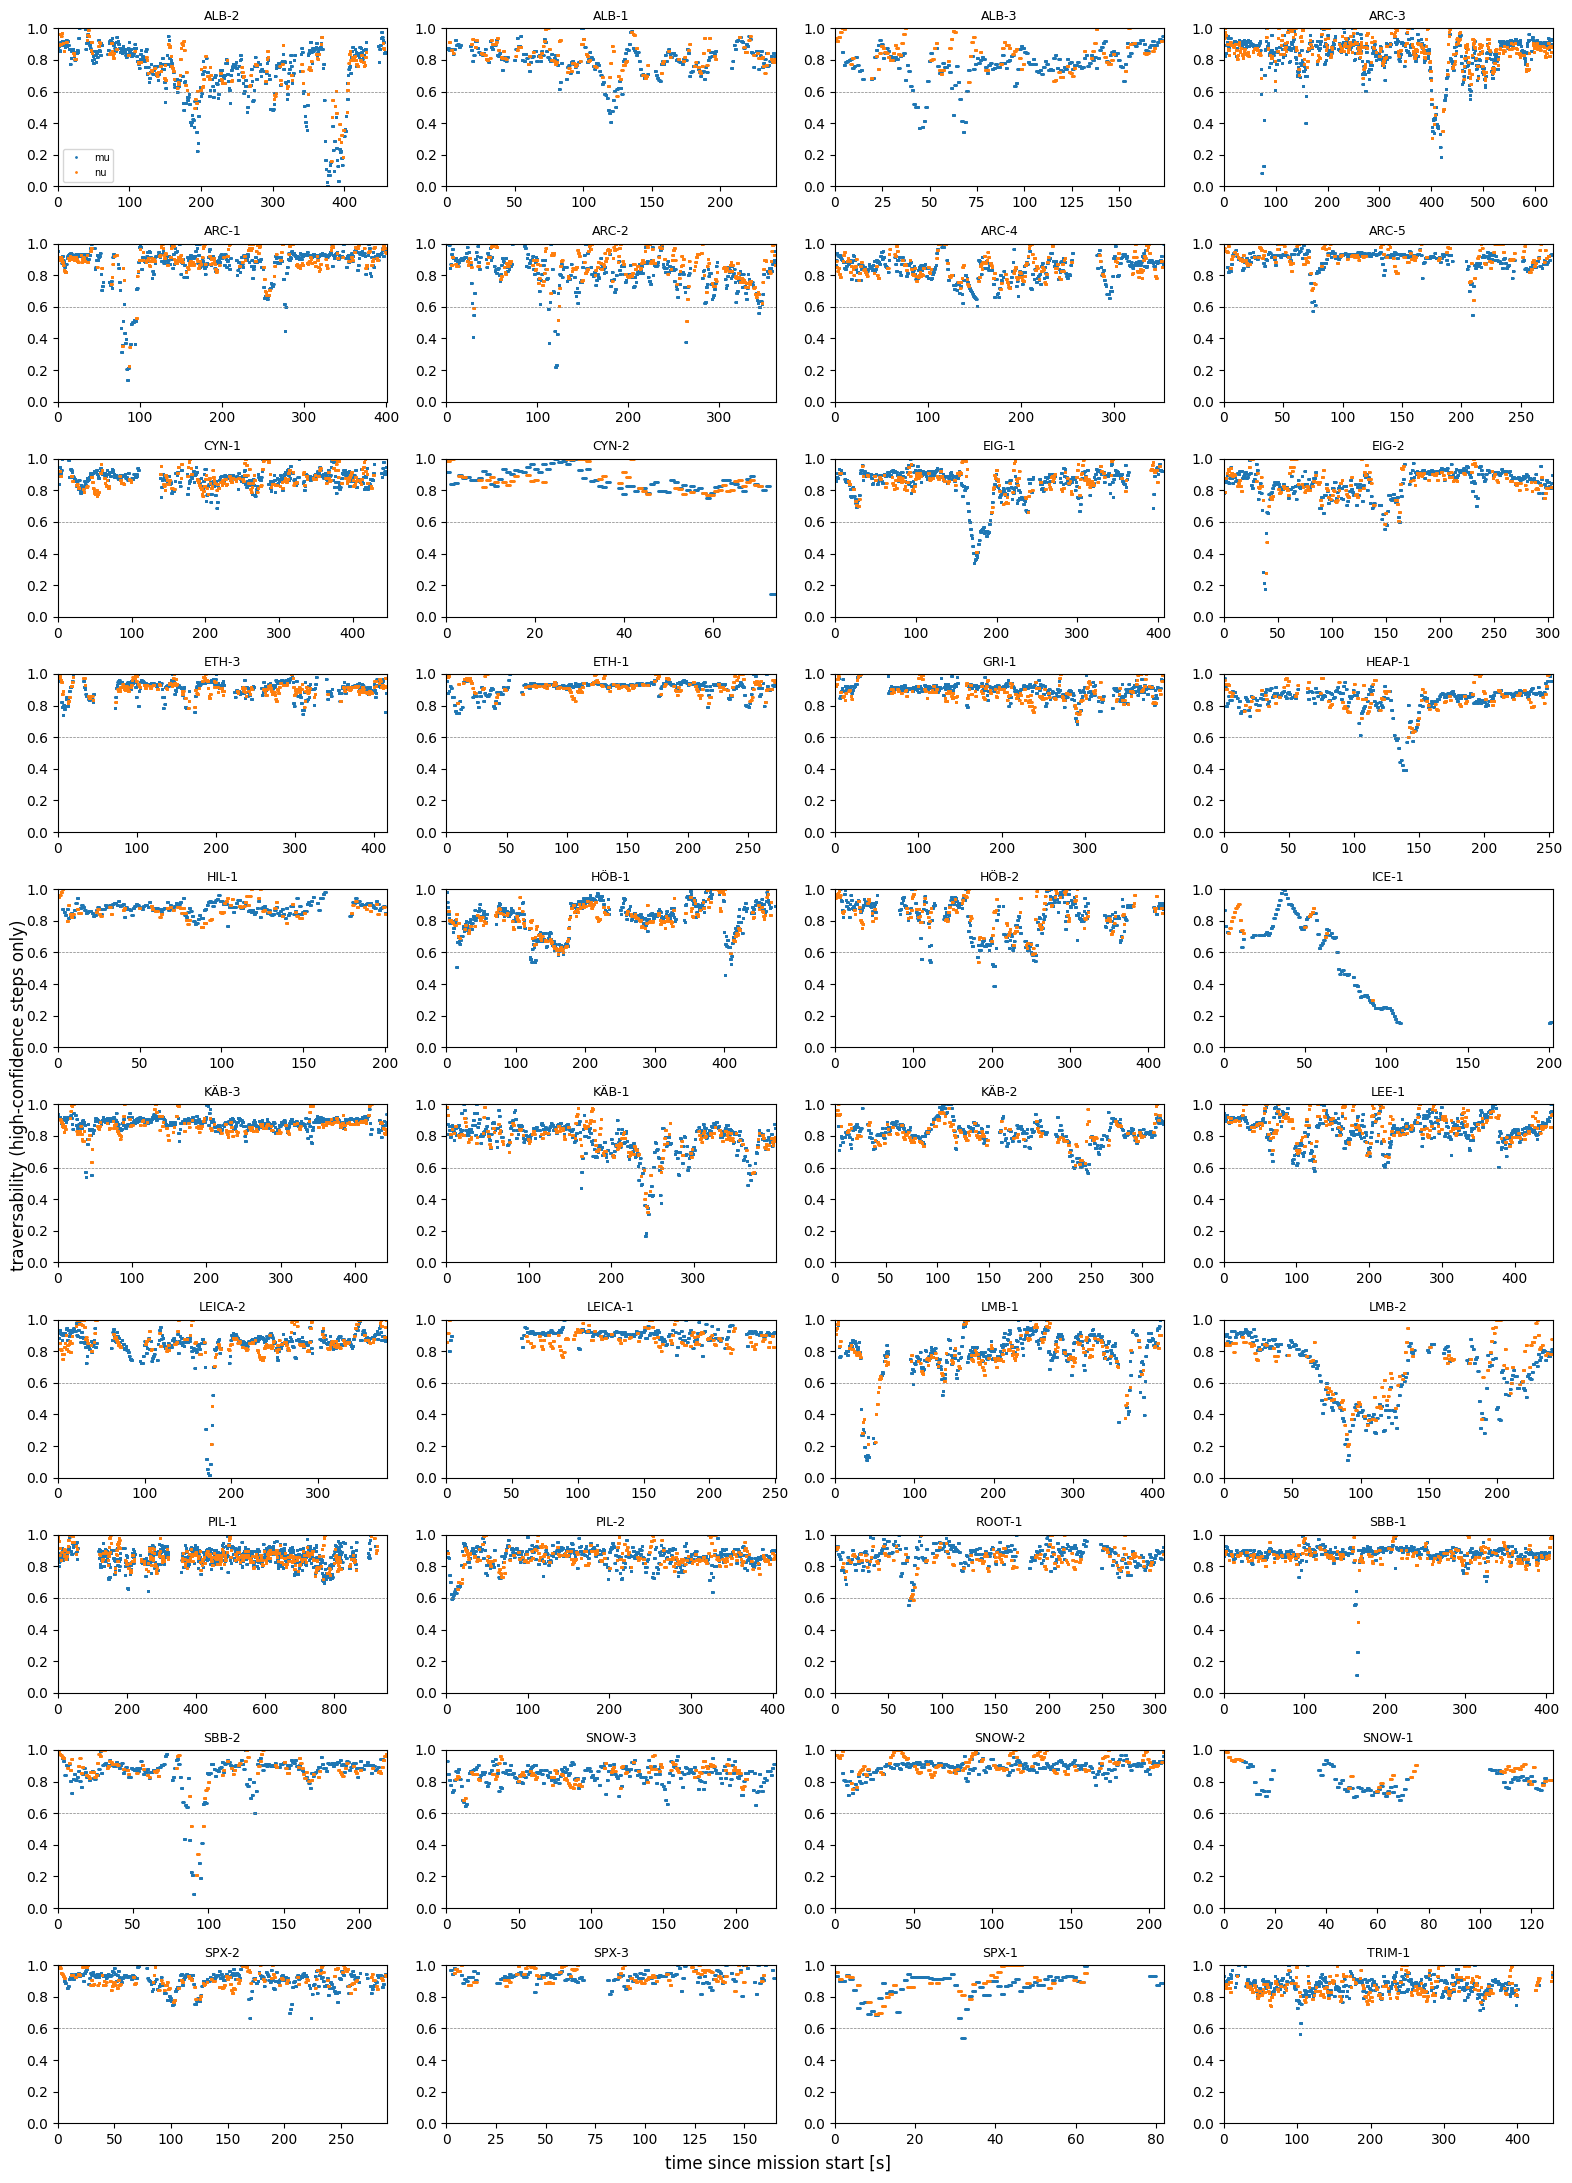

In [27]:
import matplotlib.pyplot as plt

# Per-mission mu/nu over time, masked to high-confidence steps only.
# Low-confidence steps are left blank; the x axis still spans the full mission.
missions = df.index.tolist()
ncols = 4
nrows = -(-len(missions) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.2 * nrows), squeeze=False)

for ax, m in zip(axes.flat, missions):
    d = DATA_ROOT / m
    trav = np.load(d / "trav_labels.npy")
    t = np.load(d / "timestamp.npy").astype(float)
    t = t - t[0]
    mu_c = np.load(d / "mu_confidences.npy")
    nu_c = np.load(d / "nu_confidences.npy")

    mu = np.where(mu_c > CONF_THRESH, trav[:, 0], np.nan)
    nu = np.where(nu_c > CONF_THRESH, trav[:, 1], np.nan)
    ax.plot(t, mu, ".", ms=2, label="mu")
    ax.plot(t, nu, ".", ms=2, label="nu")
    ax.axhline(LOW_THRESH, color="grey", lw=0.5, ls="--")
    ax.set_xlim(0, t[-1])
    ax.set_ylim(0, 1)
    ax.set_title(m, fontsize=9)

for ax in axes.flat[len(missions) :]:
    ax.axis("off")
axes.flat[0].legend(loc="lower left", fontsize=7)
fig.supxlabel("time since mission start [s]")
fig.supylabel("traversability (high-confidence steps only)")
fig.tight_layout()
plt.show()